In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

URL = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2025-{:02d}.parquet"
USECOLS = [
    "VendorID", "tpep_pickup_datetime", "tpep_dropoff_datetime",
    "trip_distance", "PULocationID", "DOLocationID",
    "fare_amount", "total_amount",
]
df = pd.concat(
    (pd.read_parquet(URL.format(m), columns=USECOLS) for m in range(1, 13)),
    ignore_index=True,
)
n_raw = len(df)


In [2]:
pickup = df["tpep_pickup_datetime"]
df["pickup_hour"] = pickup.dt.hour
df["pickup_month"] = pickup.dt.month
df["pickup_day"] = pickup.dt.day
df["duration_min"] = (df["tpep_dropoff_datetime"] - pickup).dt.total_seconds() / 60
speed_mph = df["trip_distance"] / (df["duration_min"] / 60)

mask = (
    (pickup.dt.year == 2025)
    & (df["duration_min"] >= 1)
    & df["trip_distance"].between(0.2, 25)
    & df["fare_amount"].between(0.01, 100)
    & (df["total_amount"] <= 125)
    & (speed_mph > 0) & (speed_mph <= 40)
)

final = df.loc[mask, [
    "VendorID", "PULocationID", "DOLocationID",
    "pickup_hour", "pickup_month", "pickup_day",
    "trip_distance", "duration_min", "fare_amount",
]].copy()
final["fare_per_mile"] = final["fare_amount"] / final["trip_distance"]  # EDA only, NOT a model feature
del df, pickup, speed_mph, mask
print(f"Rows kept: {len(final):,} ({len(final) / n_raw:.1%} of {n_raw:,})")
assert final.isna().sum().sum() == 0

Rows kept: 43,426,429 (89.1% of 48,722,602)


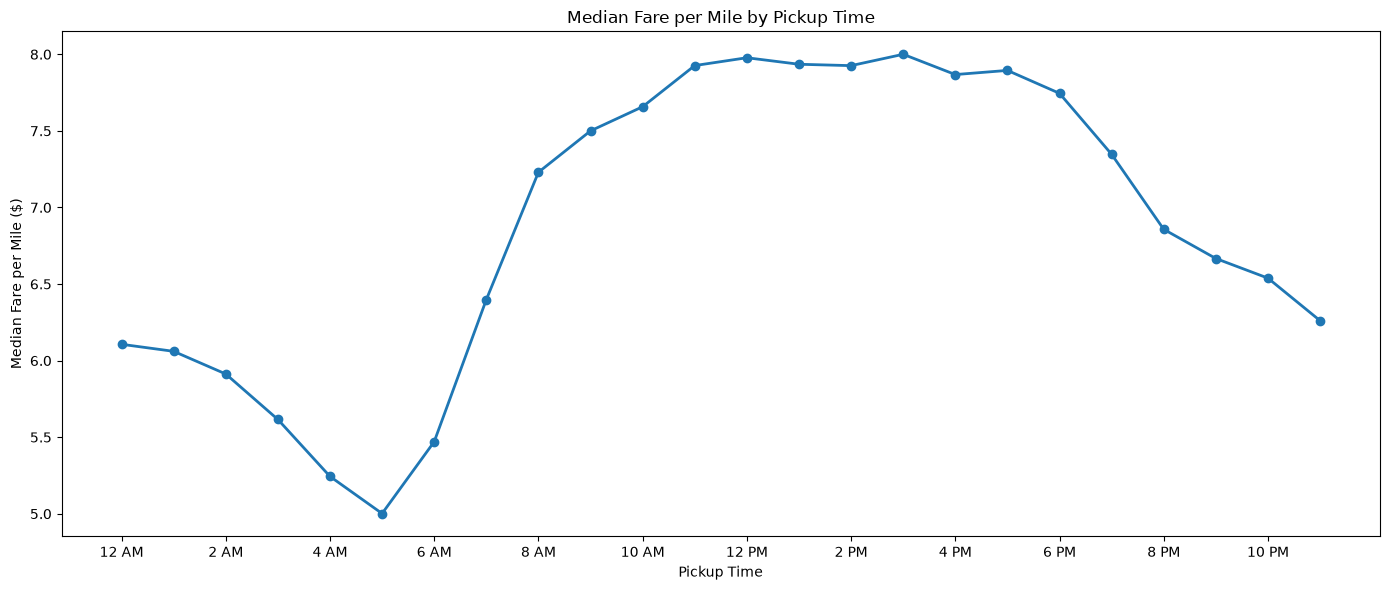

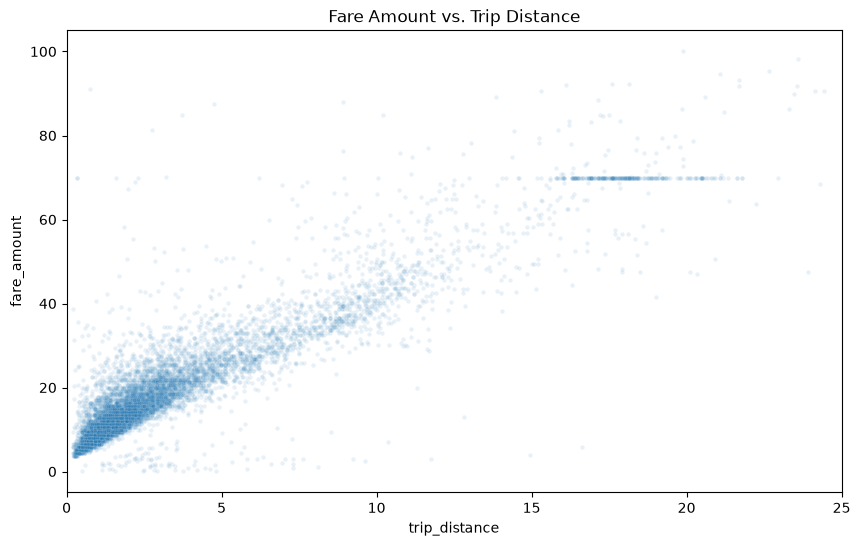

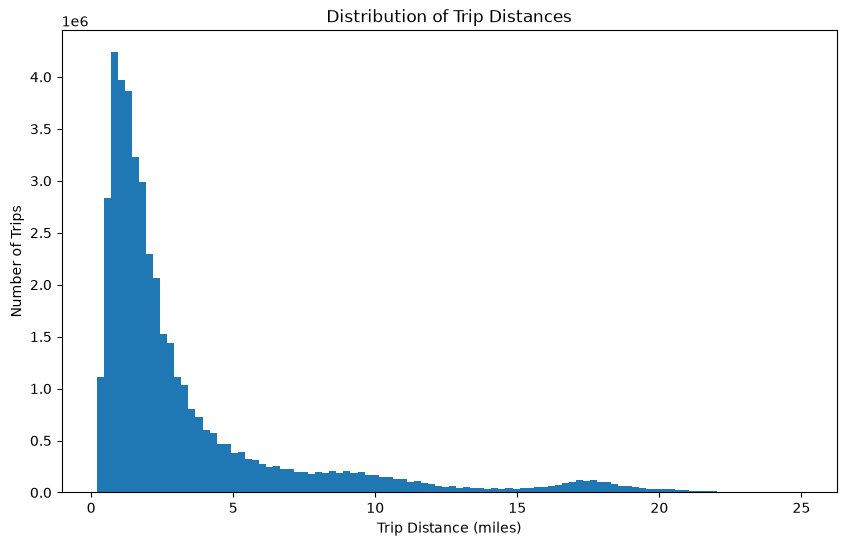

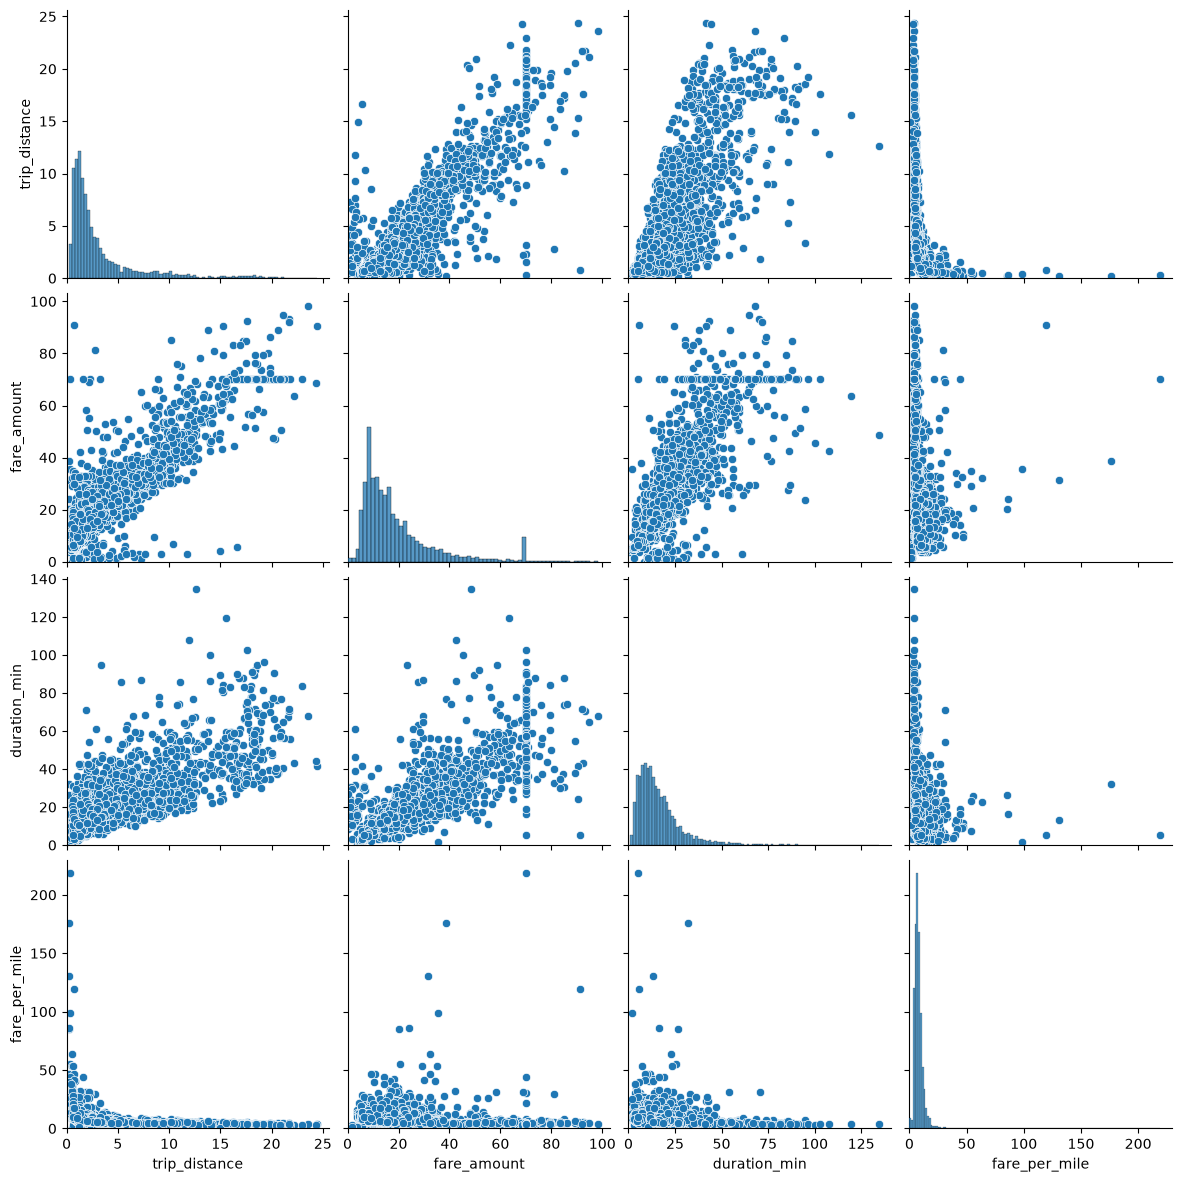

X_train: 0.83 GB | X_test: 0.21 GB
[RAM after split] kernel 7.8 GB | Mac available 11.5 GB
Saved train/test split to model_data/


In [3]:
# EDA
hourly = final.groupby("pickup_hour").agg(
    median_fare=("fare_amount", "median"),
    median_fare_per_mile=("fare_per_mile", "median"),
    median_duration=("duration_min", "median"),
    trips=("fare_amount", "count"),
).reset_index()

plt.figure(figsize=(14, 6))
plt.plot(hourly["pickup_hour"], hourly["median_fare_per_mile"], marker="o", linewidth=2)
plt.xticks(range(0, 24, 2), ["12 AM", "2 AM", "4 AM", "6 AM", "8 AM", "10 AM",
                             "12 PM", "2 PM", "4 PM", "6 PM", "8 PM", "10 PM"])
plt.xlabel("Pickup Time"); plt.ylabel("Median Fare per Mile ($)")
plt.title("Median Fare per Mile by Pickup Time")
plt.tight_layout(); plt.show()

sample = final.sample(n=10_000, random_state=42)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=sample, x="trip_distance", y="fare_amount", alpha=0.1, s=10)
plt.xlim(0, 25); plt.title("Fare Amount vs. Trip Distance"); plt.show()

plt.figure(figsize=(10, 6))
plt.hist(final["trip_distance"], bins=100)
plt.xlabel("Trip Distance (miles)"); plt.ylabel("Number of Trips")
plt.title("Distribution of Trip Distances"); plt.show()

# Hypothesis 4: multicollinearity
g = sns.pairplot(
    sample[["trip_distance", "fare_amount", "duration_min", "fare_per_mile"]].head(5000),
    height=3,
)
for ax in g.axes.flat:
    ax.set_xlim(left=0); ax.set_ylim(bottom=0)
plt.show()

# %% 4. Train / test split
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

TARGET = "fare_amount"
CAT_COLS = ["VendorID", "PULocationID", "DOLocationID"]
NUM_COLS = ["pickup_hour", "pickup_month", "pickup_day", "trip_distance", "duration_min"]
FEATURES = CAT_COLS + NUM_COLS

X_train, X_test, y_train, y_test = train_test_split(
    final[FEATURES], final[TARGET], test_size=0.2, random_state=42
)

# ---- Memory management --------------------------------------------------------
import gc
import joblib
from pathlib import Path

# The full cleaned table (~3.5 GB) is only needed for EDA; every model below uses
# X_train/X_test, which are separate copies. Free it and the EDA leftovers.
del final, sample, hourly, g
plt.close("all")

# Smaller dtypes for the features: zone/vendor IDs fit in int16/int8, hours/days/
# months in int8, and float32 is plenty for miles and minutes. Roughly halves the
# size of X_train/X_test. (Targets stay float64 so the metrics are unchanged.)
SMALL_DTYPES = {
    "VendorID": "int8", "PULocationID": "int16", "DOLocationID": "int16",
    "pickup_hour": "int8", "pickup_month": "int8", "pickup_day": "int8",
    "trip_distance": "float32", "duration_min": "float32",
}
X_train = X_train.astype(SMALL_DTYPES)
X_test = X_test.astype(SMALL_DTYPES)
gc.collect()
print(f"X_train: {X_train.memory_usage(deep=True).sum() / 1e9:.2f} GB | "
      f"X_test: {X_test.memory_usage(deep=True).sum() / 1e9:.2f} GB")

# Big models (random forest, XGBoost) are saved to disk right after they're
# evaluated and deleted from RAM, then reloaded one at a time when needed later.
MODEL_DIR = Path("saved_models")
MODEL_DIR.mkdir(exist_ok=True)

def save_model(model, name):
    path = MODEL_DIR / f"{name}.joblib"
    joblib.dump(model, path, compress=3)
    print(f"Saved {name} -> {path} ({path.stat().st_size / 1e6:.0f} MB on disk)")

def load_model(name):
    return joblib.load(MODEL_DIR / f"{name}.joblib")

def subsample(X, y, n, seed=42):
    """Random n-row sample WITHOUT copying the rest of the data.
    (train_test_split(..., train_size=n) also builds a copy of all the leftover
    rows, which briefly doubles memory before being thrown away.)"""
    if n >= len(X):
        return X, y
    idx = np.sort(np.random.default_rng(seed).choice(len(X), size=n, replace=False))
    return X.iloc[idx], y.iloc[idx]

def predict_chunked(model, X, chunk=1_000_000):
    """Predict in chunks so large intermediate arrays never exist all at once."""
    return np.concatenate([model.predict(X.iloc[i:i + chunk]) for i in range(0, len(X), chunk)])

try:
    import psutil
    def print_ram(label=""):
        used = psutil.Process().memory_info().rss / 1e9
        free = psutil.virtual_memory().available / 1e9
        print(f"[RAM {label}] kernel {used:.1f} GB | Mac available {free:.1f} GB")
except ImportError:   # run  %pip install psutil  to enable
    def print_ram(label=""):
        pass

print_ram("after split")

# Save the exact split so the neural net can be trained in its own notebook
# (NYC-NN.ipynb) with a fresh kernel: no XGBoost, forest or full dataset in RAM.
DATA_DIR = Path("model_data")
DATA_DIR.mkdir(exist_ok=True)
X_train.to_parquet(DATA_DIR / "X_train.parquet")
X_test.to_parquet(DATA_DIR / "X_test.parquet")
y_train.to_frame().to_parquet(DATA_DIR / "y_train.parquet")
y_test.to_frame().to_parquet(DATA_DIR / "y_test.parquet")
print(f"Saved train/test split to {DATA_DIR}/")

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

results = {}
results = {}
preds = {}

def evaluate(name, pred):
    pred = np.asarray(pred).reshape(-1)

    if len(pred) != len(y_test):
        raise ValueError(f"{name}: predictions don't match y_test")

    preds[name] = pred.astype("float32")   # float32 halves the memory per model

    results[name] = {
        "RMSE": rmse(y_test, pred),
        "MAE": mean_absolute_error(y_test, pred),
        "R2": r2_score(y_test, pred),
    }

    print(name, {
        k: round(v, 4)
        for k, v in results[name].items()
    })

In [4]:
# %% 4b. Hyperparameter tuning setup (shared by every model)
# How every model is tuned in this notebook:
#   1. One shared tuning set: 500k rows sampled from the TRAINING data, split into
#      400k "fit" rows and 100k "validation" rows. The same rows are used for every
#      model (including the neural net in NYC-NN.ipynb), so the comparison is fair.
#   2. Each candidate setting is fit on the 400k rows and scored on the 100k rows.
#      100k validation rows give a very stable score, so one hold-out split replaces
#      k-fold cross-validation at a fraction of the time and RAM.
#   3. The setting with the lowest validation RMSE wins and is refit on that model's
#      larger training sample. The TEST set is never used for tuning: it is touched
#      once per model, in evaluate(), so the reported scores stay honest.
#   4. RAM: only one candidate model exists at a time and it is freed before the
#      next one; nothing runs in parallel worker processes (which would each copy
#      the data, which is how GridSearchCV/RandomizedSearchCV with n_jobs=-1 use RAM).
import time
from sklearn.model_selection import ParameterSampler

TUNE_ROWS = 500_000
SELECT_BY = "MAE"              # switch to "MAE" to tune for typical error instead of big misses
LINEAR_TRAIN_ROWS = 3_000_000   # final fit for Linear and Lasso (was all ~35M rows; same result, far less RAM)

tune_X, tune_y = subsample(X_train, y_train, TUNE_ROWS, seed=7)
tune_Xtr, tune_Xval, tune_ytr, tune_yval = train_test_split(
    tune_X, tune_y, test_size=0.2, random_state=42
)
del tune_X, tune_y
gc.collect()
print(f"Tuning set: {len(tune_Xtr):,} fit rows / {len(tune_Xval):,} validation rows")

tuning_results = {}   # model name -> table of every setting tried (summarised in section 6c)

def tune(name, configs, fit_predict):
    """Try every setting in `configs`, score each on the validation rows, and return the best.
    fit_predict(params) fits one candidate on tune_Xtr/tune_ytr and returns
    (predictions for tune_Xval, dict of extra info to show in the table)."""
    rows = []
    for i, params in enumerate(configs, 1):
        t0 = time.time()
        pred, extra = fit_predict(params)
        rows.append({**params, **extra,
                     "val_RMSE": float(rmse(tune_yval, pred)),
                     "val_MAE": float(mean_absolute_error(tune_yval, pred)),
                     "secs": round(time.time() - t0, 1)})
        print(f"  [{name} {i}/{len(configs)}] {params} -> "
              f"val RMSE {rows[-1]['val_RMSE']:.4f} | val MAE {rows[-1]['val_MAE']:.4f}")
        del pred
        gc.collect()
    table = pd.DataFrame(rows)
    best_i = int(table[f"val_{SELECT_BY}"].idxmin())
    tuning_results[name] = table.sort_values(f"val_{SELECT_BY}").reset_index(drop=True)
    print(f"\n{name}: top settings by validation {SELECT_BY}")
    print(tuning_results[name].head(5).round(4).to_string(index=False))
    print_ram(f"after tuning {name}")
    return configs[best_i]

Tuning set: 400,000 fit rows / 100,000 validation rows


In [5]:
# %% 5a. Model 1: Linear regression (one-hot categoricals + scaled numerics)
# Hyperparameter tuning: none. Ordinary least squares has no settings to choose, so
# it serves as the untuned baseline. It now trains on LINEAR_TRAIN_ROWS (3M) instead
# of all ~35M rows: ~540 coefficients are fully determined long before 3M rows, and
# the one-hot matrix for 35M rows was one of the biggest RAM spikes in the notebook.
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression

linear = Pipeline([
    ("prep", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
        ("num", StandardScaler(), NUM_COLS),
    ])),
    ("reg", LinearRegression()),
])
lin_X, lin_y = subsample(X_train, y_train, LINEAR_TRAIN_ROWS)
linear.fit(lin_X, lin_y)
del lin_X, lin_y
gc.collect()
evaluate("Linear", predict_chunked(linear, X_test))
print_ram("after Linear")

Linear {'RMSE': np.float64(5.574), 'MAE': 3.3887, 'R2': 0.866}
[RAM after Linear] kernel 8.9 GB | Mac available 12.1 GB


In [6]:
# %% 5b. Model 2: Lasso, with alpha tuned
# Hyperparameter tuned: alpha, the penalty strength (Lasso's only real setting).
#   - Grid from strong (1.0) to almost none (0.0001), 9 values on a log scale.
#     Larger alpha forces more coefficients to exactly 0 (more feature selection).
#   - Tried from strong to weak with warm starts: each fit starts from the previous
#     solution, which makes the whole path fast.
#   - The one-hot/scaling step is fit once and its output reused for every alpha.
#   - Lasso's penalty is defined per row, so the chosen alpha carries over to the
#     larger final fit without rescaling.
# Earlier, LassoCV picked alpha = 0.014, which was likely the weakest value in its
# default grid, i.e. CV wanted an even smaller penalty. This grid goes 100x lower,
# so we can see whether any amount of feature selection actually helps.
from sklearn.base import clone
from sklearn.linear_model import Lasso

LASSO_ALPHAS = np.logspace(0, -4, 9)   # 1, 0.32, 0.1, ..., 0.0001

lasso_prep = clone(linear.named_steps["prep"]).fit(tune_Xtr)
Z_tr, Z_val = lasso_prep.transform(tune_Xtr), lasso_prep.transform(tune_Xval)
path_model = Lasso(max_iter=5000, warm_start=True)

def lasso_fit_predict(p):
    path_model.set_params(alpha=p["alpha"])
    path_model.fit(Z_tr, tune_ytr)
    return path_model.predict(Z_val), {"nonzero_coefs": int((path_model.coef_ != 0).sum())}

best = tune("Lasso", [{"alpha": float(a)} for a in LASSO_ALPHAS], lasso_fit_predict)
best_alpha = best["alpha"]
del lasso_prep, Z_tr, Z_val, path_model
gc.collect()
if best_alpha == LASSO_ALPHAS.min():
    print("\nNote: the weakest penalty won. Feature selection is not reducing error for "
          "this model; Lasso here is effectively plain linear regression.")

lasso = Pipeline([
    ("prep", clone(linear.named_steps["prep"])),
    ("reg", Lasso(alpha=best_alpha, max_iter=5000)),
])
las_X, las_y = subsample(X_train, y_train, LINEAR_TRAIN_ROWS)
lasso.fit(las_X, las_y)
del las_X, las_y
gc.collect()
evaluate("Lasso", predict_chunked(lasso, X_test))

# Which inputs did Lasso keep? (counts nonzero coefficients per original feature)
lasso_coef = lasso.named_steps["reg"].coef_
lasso_names = lasso.named_steps["prep"].get_feature_names_out()   # e.g. "cat__PULocationID_132"
kinds, cols = zip(*(n.split("__", 1) for n in lasso_names))
groups = [c.rsplit("_", 1)[0] if k == "cat" else c for k, c in zip(kinds, cols)]
selection = (pd.DataFrame({"feature": groups, "kept": lasso_coef != 0})
             .groupby("feature")["kept"].agg(kept="sum", total="size"))
print("\nLasso feature selection (nonzero coefficients / total columns):")
print(selection)
print_ram("after Lasso")

  [Lasso 1/9] {'alpha': 1.0} -> val RMSE 6.0050 | val MAE 3.7427
  [Lasso 2/9] {'alpha': 0.31622776601683794} -> val RMSE 5.9013 | val MAE 3.5259
  [Lasso 3/9] {'alpha': 0.1} -> val RMSE 5.8807 | val MAE 3.4620
  [Lasso 4/9] {'alpha': 0.03162277660168379} -> val RMSE 5.8439 | val MAE 3.4340
  [Lasso 5/9] {'alpha': 0.01} -> val RMSE 5.7345 | val MAE 3.4012
  [Lasso 6/9] {'alpha': 0.0031622776601683794} -> val RMSE 5.6609 | val MAE 3.3785
  [Lasso 7/9] {'alpha': 0.001} -> val RMSE 5.6246 | val MAE 3.3653
  [Lasso 8/9] {'alpha': 0.00031622776601683794} -> val RMSE 5.6050 | val MAE 3.3564
  [Lasso 9/9] {'alpha': 0.0001} -> val RMSE 5.6010 | val MAE 3.3563

Lasso: top settings by validation MAE
 alpha  nonzero_coefs  val_RMSE  val_MAE  secs
0.0001            427    5.6010   3.3563   3.7
0.0003            336    5.6050   3.3564   1.1
0.0010            190    5.6246   3.3653   0.4
0.0032            102    5.6609   3.3785   0.3
0.0100             43    5.7345   3.4012   0.3
[RAM after tuning L

In [7]:
import os
print("Current notebook PID:", os.getpid())

Current notebook PID: 19202


In [8]:
# %% 5c. Polynomial (higher-order) linear regression, with degree and ridge alpha tuned
# Expands the 5 numeric features into squares and products (e.g. trip_distance²,
# trip_distance × duration_min); zones/vendor stay one-hot exactly as in Linear.
# Zones are NOT expanded: zone × zone would mean ~70,000 extra columns.
#
# Hyperparameters tuned (grid search, every combination = 15 settings):
#   - degree (2, 3, 4): how much curvature/interaction the model may use.
#   - alpha (ridge penalty): shrinks the many highly correlated power terms.
#     Higher degrees need more of it: with a fixed tiny penalty, degree 4 blew up on
#     unusual test trips earlier (test RMSE $64), and choosing the degree by looking
#     at test scores would have been tuning on the test set.
# The expansion is computed once per degree and reused for every alpha.
# Ridge's penalty is NOT divided by the number of rows, so the chosen alpha is
# scaled up by (final rows / tuning rows) to keep the same strength in the final fit.
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge

POLY_DEGREES = [2, 3, 4]
RIDGE_ALPHAS = [0.1, 1, 10, 100, 1000]
POLY_TRAIN_ROWS = 1_000_000   # degree 4 has ~130 numeric terms per row; keeps the sparse matrix small

def make_poly(degree, alpha):
    return Pipeline([
        ("prep", ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
            ("num", Pipeline([
                ("scale", StandardScaler()),
                ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
                ("rescale", StandardScaler()),   # power terms have very different scales
            ]), NUM_COLS),
        ])),
        ("reg", Ridge(alpha=alpha)),
    ])

_poly_cache = {}
def poly_fit_predict(p):
    if _poly_cache.get("degree") != p["degree"]:   # new degree: expand once, drop the old expansion
        _poly_cache.clear()
        gc.collect()
        prep = make_poly(p["degree"], 1.0).named_steps["prep"].fit(tune_Xtr)
        _poly_cache.update(degree=p["degree"], tr=prep.transform(tune_Xtr), val=prep.transform(tune_Xval))
    reg = Ridge(alpha=p["alpha"]).fit(_poly_cache["tr"], tune_ytr)
    return reg.predict(_poly_cache["val"]), {}

best = tune("Poly", [{"degree": d, "alpha": a} for d in POLY_DEGREES for a in RIDGE_ALPHAS],
            poly_fit_predict)
_poly_cache.clear()
gc.collect()

best_degree = best["degree"]
final_alpha = best["alpha"] * POLY_TRAIN_ROWS / len(tune_Xtr)
print(f"\nRefitting degree {best_degree} on {POLY_TRAIN_ROWS:,} rows with alpha "
      f"{final_alpha:g} (tuned {best['alpha']:g}, scaled to the larger sample)")

poly_model = make_poly(best_degree, final_alpha)
poly_X, poly_y = subsample(X_train, y_train, POLY_TRAIN_ROWS)
poly_model.fit(poly_X, poly_y)
del poly_X, poly_y
gc.collect()

poly_models = {f"Poly{best_degree}": poly_model}   # used by the diagnostics cell below
evaluate(f"Poly{best_degree}", predict_chunked(poly_model, X_test))
print_ram("after Poly")

  [Poly 1/15] {'degree': 2, 'alpha': 0.1} -> val RMSE 4.9056 | val MAE 2.3924
  [Poly 2/15] {'degree': 2, 'alpha': 1} -> val RMSE 4.9051 | val MAE 2.3922
  [Poly 3/15] {'degree': 2, 'alpha': 10} -> val RMSE 4.9024 | val MAE 2.3901
  [Poly 4/15] {'degree': 2, 'alpha': 100} -> val RMSE 4.9221 | val MAE 2.3936
  [Poly 5/15] {'degree': 2, 'alpha': 1000} -> val RMSE 5.0438 | val MAE 2.4312
  [Poly 6/15] {'degree': 3, 'alpha': 0.1} -> val RMSE 4.6492 | val MAE 2.0543
  [Poly 7/15] {'degree': 3, 'alpha': 1} -> val RMSE 4.6484 | val MAE 2.0536
  [Poly 8/15] {'degree': 3, 'alpha': 10} -> val RMSE 4.6454 | val MAE 2.0535
  [Poly 9/15] {'degree': 3, 'alpha': 100} -> val RMSE 4.6642 | val MAE 2.0630
  [Poly 10/15] {'degree': 3, 'alpha': 1000} -> val RMSE 4.7963 | val MAE 2.1574
  [Poly 11/15] {'degree': 4, 'alpha': 0.1} -> val RMSE 4.5398 | val MAE 1.9943
  [Poly 12/15] {'degree': 4, 'alpha': 1} -> val RMSE 4.5393 | val MAE 1.9946
  [Poly 13/15] {'degree': 4, 'alpha': 10} -> val RMSE 4.5401 | val 

Linear: residual skew 1.84, excess kurtosis 22.4
Lasso: residual skew 1.85, excess kurtosis 22.4
Poly4: residual skew 2.62, excess kurtosis 41.9


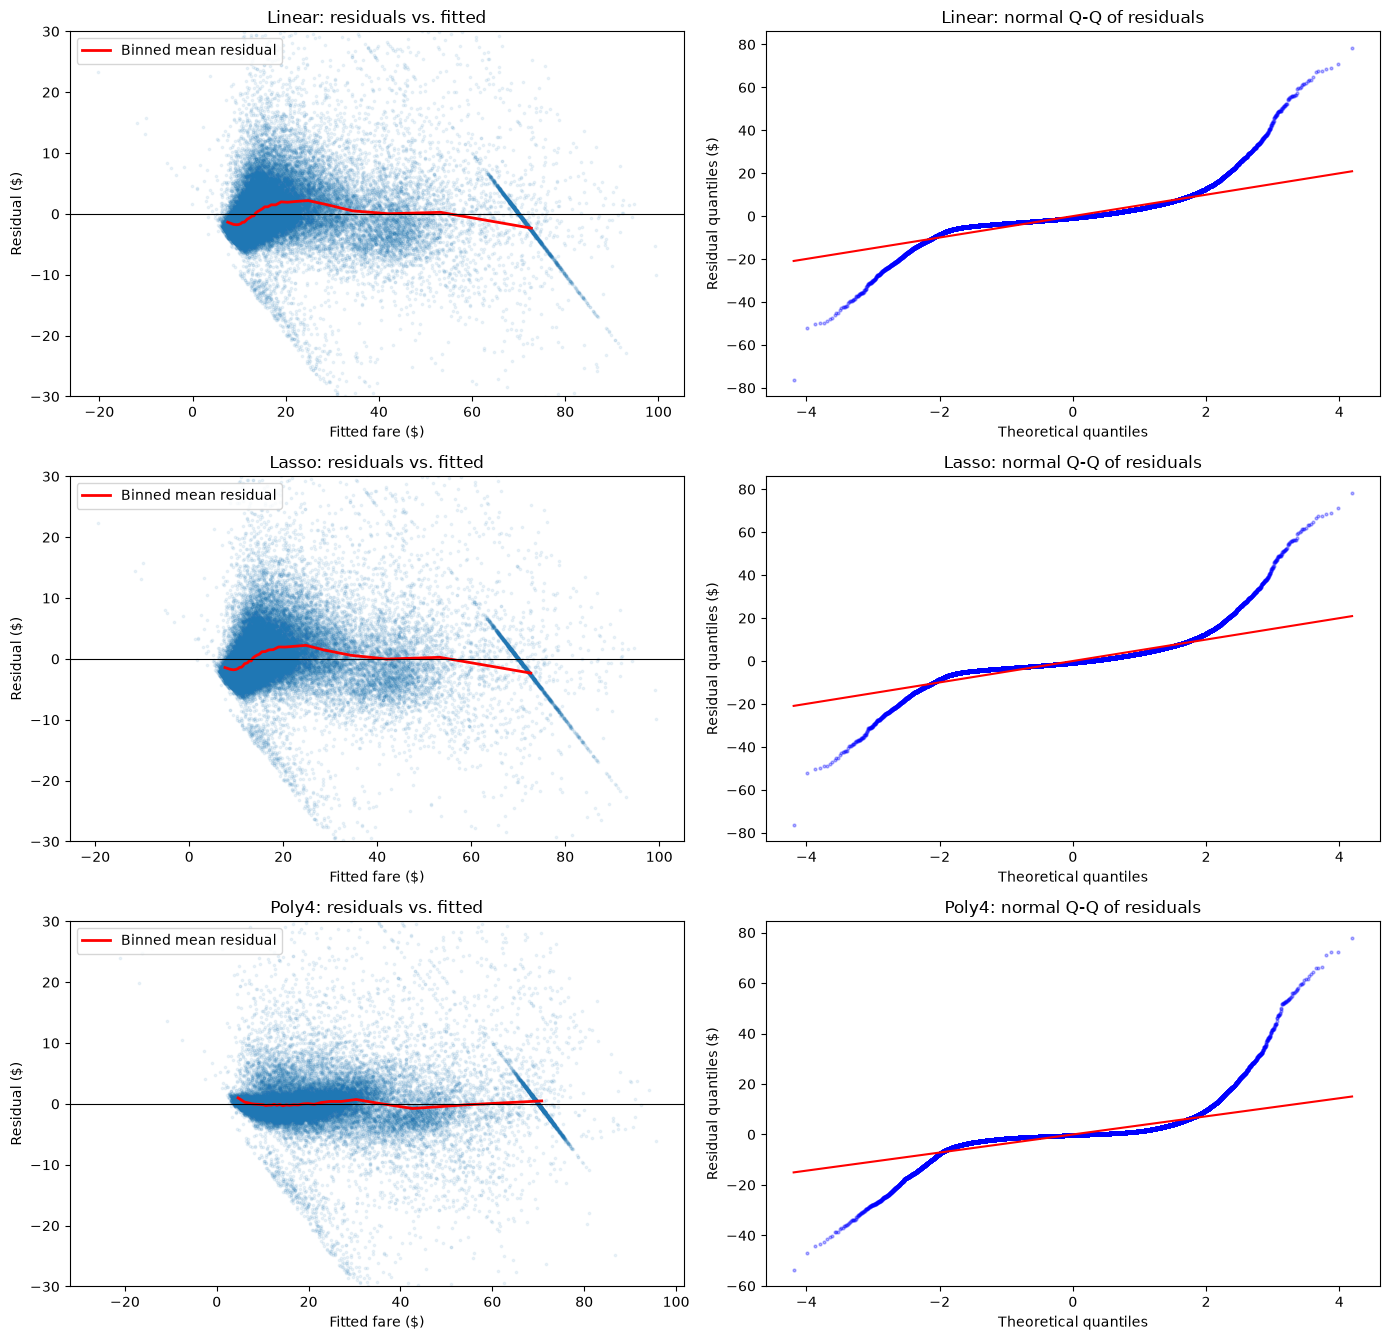

In [9]:
# %% 5d. Residual diagnostics for the linear-family models
# Residuals vs. fitted: ideally a flat, even band around 0.
#   - Red line curving away from 0 = nonlinearity the model is missing.
#   - Band widening to the right (a funnel) = errors grow with fare size
#     (heteroscedasticity).
# Normal Q-Q plot: points on the straight line = normally distributed residuals.
#   - Ends bending away from the line (an S-shape) = heavier tails than normal,
#     i.e. occasional large misses, which is what pushes RMSE well above MAE.
# Plotted on a random test sample: millions of points would add nothing visually.
from scipy import stats

DIAG_ROWS = 50_000
diag_X = X_test.sample(min(DIAG_ROWS, len(X_test)), random_state=1)
diag_y = y_test.loc[diag_X.index].to_numpy()

lin_models = {"Linear": linear, "Lasso": lasso, **poly_models}

fig, axes = plt.subplots(len(lin_models), 2, figsize=(14, 4.5 * len(lin_models)))
for (name, model), (ax_rf, ax_qq) in zip(lin_models.items(), axes):
    fitted = model.predict(diag_X)
    resid = diag_y - fitted

    # Residuals vs. fitted, with a binned-mean line to show systematic bias
    ax_rf.scatter(fitted, resid, s=3, alpha=0.08)
    bins = pd.qcut(fitted, 30, duplicates="drop")
    binned = pd.DataFrame({"f": fitted, "r": resid}).groupby(bins, observed=True).mean()
    ax_rf.plot(binned["f"], binned["r"], color="red", linewidth=2, label="Binned mean residual")
    ax_rf.axhline(0, color="k", linewidth=0.8)
    ax_rf.set_ylim(-30, 30)   # zoomed view; a few larger residuals fall outside
    ax_rf.set_xlabel("Fitted fare ($)"); ax_rf.set_ylabel("Residual ($)")
    ax_rf.set_title(f"{name}: residuals vs. fitted"); ax_rf.legend(loc="upper left")

    # Normal Q-Q plot of the residuals
    stats.probplot(resid, dist="norm", plot=ax_qq)
    ax_qq.get_lines()[0].set(markersize=2, alpha=0.3)
    ax_qq.set_title(f"{name}: normal Q-Q of residuals")
    ax_qq.set_ylabel("Residual quantiles ($)")

    print(f"{name}: residual skew {stats.skew(resid):.2f}, "
          f"excess kurtosis {stats.kurtosis(resid):.1f}")   # normal = 0 and 0

plt.tight_layout(); plt.show()
del diag_X, diag_y

In [10]:
# %% 5e. XGBoost, with a random search over its main settings
# Hyperparameters tuned (random search: 15 combinations drawn from the grid below,
# since trying all 972 would take hours):
#   - max_depth: how complex each tree can get (interaction depth).
#   - learning_rate: how much each new tree corrects the previous ones.
#   - min_child_weight: minimum data in a leaf; larger = smoother trees.
#   - subsample / colsample_bytree: fraction of rows / features each tree sees
#     (randomness that reduces overfitting).
#   - reg_lambda: L2 penalty on leaf values.
#   - n_estimators (number of trees) is not searched: every candidate trains with
#     early stopping on the validation rows, which picks it automatically.
# RAM: tree_method="hist" bins the data into a compact form, 4 threads, one model at a time.
from xgboost import XGBRegressor

XGB_SPACE = {
    "max_depth": [4, 6, 8, 10],
    "learning_rate": [0.05, 0.1, 0.2],
    "min_child_weight": [1, 5, 20],
    "subsample": [0.7, 0.85, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "reg_lambda": [0.5, 1.0, 5.0],
}
XGB_N_ITER = 15
XGB_TRAIN_ROWS = 2_000_000
XGB_COMMON = dict(tree_method="hist", objective="reg:squarederror", eval_metric="rmse",
                  n_jobs=4, random_state=42)

def xgb_fit_predict(p):
    m = XGBRegressor(n_estimators=2000, early_stopping_rounds=30, **XGB_COMMON, **p)
    m.fit(tune_Xtr, tune_ytr, eval_set=[(tune_Xval, tune_yval)], verbose=False)
    pred = m.predict(tune_Xval)          # uses the early-stopped best iteration
    n_trees = m.best_iteration + 1
    del m
    return pred, {"trees": n_trees}

xgb_configs = list(ParameterSampler(XGB_SPACE, n_iter=XGB_N_ITER, random_state=42))
best = tune("XGBoost", xgb_configs, xgb_fit_predict)

# Final model: best settings on the larger sample. It gets its own 5% early-stopping
# split, and a higher tree cap because more data supports more trees (the previous
# version hit its 500-tree cap while still improving).
xgb_X, xgb_y = subsample(X_train, y_train, XGB_TRAIN_ROWS)
xgb_Xtr, xgb_Xval, xgb_ytr, xgb_yval = train_test_split(xgb_X, xgb_y, test_size=0.05, random_state=42)
del xgb_X, xgb_y

xgb = XGBRegressor(n_estimators=4000, early_stopping_rounds=50, **XGB_COMMON, **best)
xgb.fit(xgb_Xtr, xgb_ytr, eval_set=[(xgb_Xval, xgb_yval)], verbose=250)
print(f"Final XGBoost: {xgb.best_iteration + 1} trees")
del xgb_Xtr, xgb_Xval, xgb_ytr, xgb_yval
gc.collect()

evaluate("XGBoost", predict_chunked(xgb, X_test))

# Move the model to disk
save_model(xgb, "xgboost")
del xgb
gc.collect()
print_ram("after XGBoost saved + freed")

  [XGBoost 1/15] {'subsample': 1.0, 'reg_lambda': 0.5, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 1.0} -> val RMSE 4.1472 | val MAE 1.7868
  [XGBoost 2/15] {'subsample': 0.85, 'reg_lambda': 5.0, 'min_child_weight': 5, 'max_depth': 8, 'learning_rate': 0.05, 'colsample_bytree': 0.6} -> val RMSE 4.0586 | val MAE 1.7783
  [XGBoost 3/15] {'subsample': 0.7, 'reg_lambda': 0.5, 'min_child_weight': 20, 'max_depth': 10, 'learning_rate': 0.1, 'colsample_bytree': 1.0} -> val RMSE 4.1216 | val MAE 1.7648
  [XGBoost 4/15] {'subsample': 1.0, 'reg_lambda': 5.0, 'min_child_weight': 20, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 0.8} -> val RMSE 4.0858 | val MAE 1.7725
  [XGBoost 5/15] {'subsample': 1.0, 'reg_lambda': 1.0, 'min_child_weight': 20, 'max_depth': 10, 'learning_rate': 0.2, 'colsample_bytree': 0.8} -> val RMSE 4.1209 | val MAE 1.8188
  [XGBoost 6/15] {'subsample': 0.85, 'reg_lambda': 1.0, 'min_child_weight': 20, 'max_depth': 10, 'learning_r

In [11]:
# %% 5f. Random forest, with a random search over its main settings
# Hyperparameters tuned (random search: 10 combinations from 48):
#   - max_features: fraction of features considered at each split. Lower = more
#     varied trees, which usually helps the average.
#   - min_samples_leaf: smallest allowed leaf. Smaller = more detailed trees, but
#     bigger in RAM and more prone to fitting noise.
#   - max_depth: hard cap on tree depth.
# Tuning uses 40 trees per candidate instead of 100: adding trees only smooths the
# average, it rarely changes which settings rank best, and it halves the time.
# RAM: trees are built 4 at a time, each candidate is freed before the next, and a
# guard below shrinks the final forest if the chosen settings would exceed RF_MAX_GB.
from sklearn.ensemble import RandomForestRegressor

RF_SPACE = {
    "max_features": [0.33, 0.5, 0.75, 1.0],
    "min_samples_leaf": [5, 10, 20, 50],
    "max_depth": [16, 20, 24],
}
RF_N_ITER = 10
RF_TUNE_TREES = 40
RF_FINAL_TREES = 100
RF_TRAIN_ROWS = 1_000_000
RF_MAX_SAMPLES = 0.5   # bootstrap sample per tree, as a fraction of the training rows
RF_JOBS = 4
RF_MAX_GB = 1.5        # RAM budget for the final forest

def make_rf(n_estimators, **p):
    return RandomForestRegressor(n_estimators=n_estimators, max_samples=RF_MAX_SAMPLES,
                                 n_jobs=RF_JOBS, random_state=42, **p)

def rf_fit_predict(p):
    m = make_rf(RF_TUNE_TREES, **p).fit(tune_Xtr, tune_ytr)
    pred = m.predict(tune_Xval)
    avg_nodes = int(np.mean([t.tree_.node_count for t in m.estimators_]))
    del m
    return pred, {"avg_nodes_per_tree": avg_nodes}

rf_configs = list(ParameterSampler(RF_SPACE, n_iter=RF_N_ITER, random_state=42))
best = tune("RandomForest", rf_configs, rf_fit_predict)

# RAM guard: a tree has at most ~2 x (rows per tree / min_samples_leaf) nodes of
# ~80 bytes each. If the chosen leaf size would make the final forest too big,
# double it until the upper-bound estimate fits the budget.
def est_forest_gb(min_leaf):
    rows_per_tree = RF_TRAIN_ROWS * RF_MAX_SAMPLES
    return 2 * rows_per_tree / min_leaf * 80 * RF_FINAL_TREES / 1e9

final_rf_params = dict(best)
while est_forest_gb(final_rf_params["min_samples_leaf"]) > RF_MAX_GB:
    final_rf_params["min_samples_leaf"] *= 2
if final_rf_params != best:
    print(f"RAM guard: min_samples_leaf raised {best['min_samples_leaf']} -> "
          f"{final_rf_params['min_samples_leaf']} to keep the forest under {RF_MAX_GB} GB")
print(f"Final forest upper-bound size: {est_forest_gb(final_rf_params['min_samples_leaf']):.2f} GB")

print_ram("before final RF")
rf_X, rf_y = subsample(X_train, y_train, RF_TRAIN_ROWS)
rf = make_rf(RF_FINAL_TREES, **final_rf_params).fit(rf_X, rf_y)
del rf_X, rf_y
gc.collect()
print_ram("after final RF fit")

evaluate("RandomForest", predict_chunked(rf, X_test))

# Keep the forest on disk, not in RAM
save_model(rf, "random_forest")
del rf
gc.collect()
print_ram("after RF saved + freed")

  [RandomForest 1/10] {'min_samples_leaf': 50, 'max_features': 0.75, 'max_depth': 20} -> val RMSE 4.5892 | val MAE 1.7937
  [RandomForest 2/10] {'min_samples_leaf': 5, 'max_features': 0.75, 'max_depth': 24} -> val RMSE 4.3728 | val MAE 1.7742
  [RandomForest 3/10] {'min_samples_leaf': 20, 'max_features': 0.75, 'max_depth': 20} -> val RMSE 4.5074 | val MAE 1.7758
  [RandomForest 4/10] {'min_samples_leaf': 50, 'max_features': 0.75, 'max_depth': 24} -> val RMSE 4.5793 | val MAE 1.7917
  [RandomForest 5/10] {'min_samples_leaf': 5, 'max_features': 0.75, 'max_depth': 20} -> val RMSE 4.3744 | val MAE 1.7687
  [RandomForest 6/10] {'min_samples_leaf': 10, 'max_features': 0.5, 'max_depth': 24} -> val RMSE 4.4046 | val MAE 1.7616
  [RandomForest 7/10] {'min_samples_leaf': 5, 'max_features': 1.0, 'max_depth': 16} -> val RMSE 4.3845 | val MAE 1.7629
  [RandomForest 8/10] {'min_samples_leaf': 50, 'max_features': 0.33, 'max_depth': 20} -> val RMSE 4.5927 | val MAE 1.8972
  [RandomForest 9/10] {'min_s

In [12]:
# %% 5g. Neural net: trained in NYC-NN.ipynb, loaded here
# The network itself is small; the crashes came from training it in a kernel that
# already held the data, the other models and XGBoost's threading library. It now
# runs in its own notebook and saves its test-set predictions here.
nn_pred_path = MODEL_DIR / "nn_test_preds.npy"
nn_index_path = MODEL_DIR / "nn_test_index.npy"

if not nn_pred_path.exists():
    print("No neural-net predictions yet: run NYC-NN.ipynb, then re-run this cell and the ones below.")
elif not np.array_equal(np.load(nn_index_path), X_test.index.to_numpy()):
    print("Saved neural-net predictions are for a different test set: re-run NYC-NN.ipynb.")
else:
    evaluate("NeuralNet", np.load(nn_pred_path))

NeuralNet {'RMSE': np.float64(3.9971), 'MAE': 1.6496, 'R2': 0.9311}


                 RMSE     MAE      R2  RMSE rank  MAE rank
XGBoost        3.9481  1.6938  0.9328          1         2
NeuralNet      3.9971  1.6496  0.9311          2         1
RandomForest   4.2870  1.7220  0.9208          3         3
Linear         5.5740  3.3887  0.8660          4         6
Lasso          5.5752  3.3880  0.8660          5         5
Poly4         41.0506  2.0418 -6.2663          6         4

Absolute error quantiles ($):
              0.500  0.900  0.990  0.999
Linear         2.33   6.72  22.16  49.12
Lasso          2.33   6.72  22.17  49.19
Poly4          0.83   4.38  20.38  46.86
XGBoost        0.61   3.97  17.71  40.66
RandomForest   0.57   3.93  19.74  46.29
NeuralNet      0.56   3.82  18.39  41.15

Residual skewness (actual - predicted):
Linear             1.66100
Lasso              1.66000
Poly4          -1923.18103
XGBoost            2.93300
RandomForest       2.90200
NeuralNet          2.77600
dtype: float32


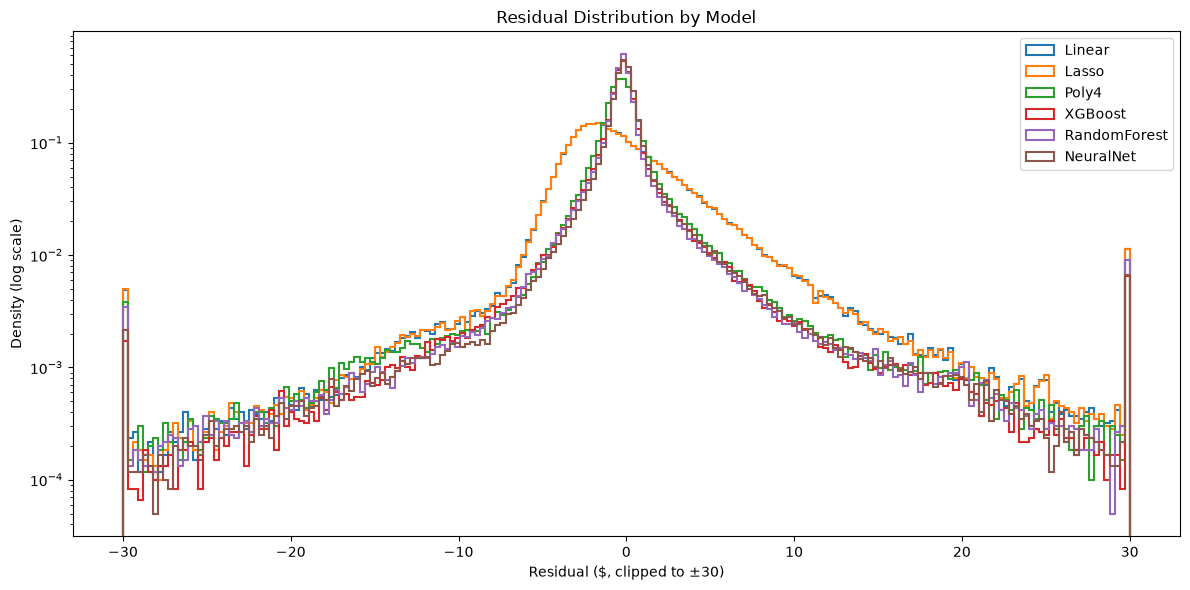

11016

In [13]:
res = pd.DataFrame(results).T
res["RMSE rank"] = res["RMSE"].rank().astype(int)
res["MAE rank"] = res["MAE"].rank().astype(int)
print(res.sort_values("RMSE").round(4))
# If the two rank columns disagree, the models differ mainly in how they handle
# the tail of large errors; look at the diagnostics below before picking a winner.

# %% 6b. Error distribution: are errors skewed?
y_true = y_test.to_numpy(dtype="float32")
abs_err = pd.DataFrame({n: np.abs(y_true - p) for n, p in preds.items()})
print("\nAbsolute error quantiles ($):")
print(abs_err.quantile([0.5, 0.9, 0.99, 0.999]).T.round(2))

resid = pd.DataFrame({n: y_true - p for n, p in preds.items()})
print("\nResidual skewness (actual - predicted):")
print(resid.skew().round(3))

plt.figure(figsize=(12, 6))
resid_sample = resid.sample(200_000, random_state=0)
for name in resid_sample.columns:
    plt.hist(resid_sample[name].clip(-30, 30), bins=200, histtype="step",
             linewidth=1.5, label=name, density=True)
plt.yscale("log")
plt.xlabel("Residual ($, clipped to ±30)"); plt.ylabel("Density (log scale)")
plt.title("Residual Distribution by Model")
plt.legend(); plt.tight_layout(); plt.show()
del abs_err, resid, resid_sample, y_true
gc.collect()

In [14]:
# %% 6c. Hyperparameter tuning summary
# Every setting tried for every model, best first, scored on the shared validation
# rows (never the test set). The neural net's search ran in NYC-NN.ipynb.
nn_tune_path = MODEL_DIR / "nn_tuning.parquet"
if nn_tune_path.exists():
    tuning_results["NeuralNet"] = pd.read_parquet(nn_tune_path)
else:
    print("Neural-net tuning table not found: run NYC-NN.ipynb to include it.\n")

summary = []
for name, table in tuning_results.items():
    best_row = table.iloc[0]
    worst_row = table.iloc[-1]
    summary.append({
        "model": name,
        "settings tried": len(table),
        "best val RMSE": best_row["val_RMSE"],
        "worst val RMSE": worst_row["val_RMSE"],
        "best val MAE": best_row["val_MAE"],
    })
    print(f"=== {name}: {len(table)} settings tried, best first ===")
    print(table.head(3).round(4).to_string(index=False), "\n")

print("How much tuning mattered (gap between best and worst setting):")
print(pd.DataFrame(summary).set_index("model").round(4))

=== Lasso: 9 settings tried, best first ===
 alpha  nonzero_coefs  val_RMSE  val_MAE  secs
0.0001            427    5.6010   3.3563   3.7
0.0003            336    5.6050   3.3564   1.1
0.0010            190    5.6246   3.3653   0.4 

=== Poly: 15 settings tried, best first ===
 degree  alpha  val_RMSE  val_MAE  secs
      4    0.1    4.5398   1.9943  28.6
      4    1.0    4.5393   1.9946  26.5
      4   10.0    4.5401   1.9974  17.2 

=== XGBoost: 15 settings tried, best first ===
 subsample  reg_lambda  min_child_weight  max_depth  learning_rate  colsample_bytree  trees  val_RMSE  val_MAE  secs
       0.7         1.0                 5          8           0.05               1.0    667    4.0842   1.7413   3.6
       1.0         5.0                 5          6           0.10               1.0    692    4.0922   1.7580   2.6
       0.7         0.5                20         10           0.10               1.0    239    4.1216   1.7648   1.7 

=== RandomForest: 10 settings tried, best f

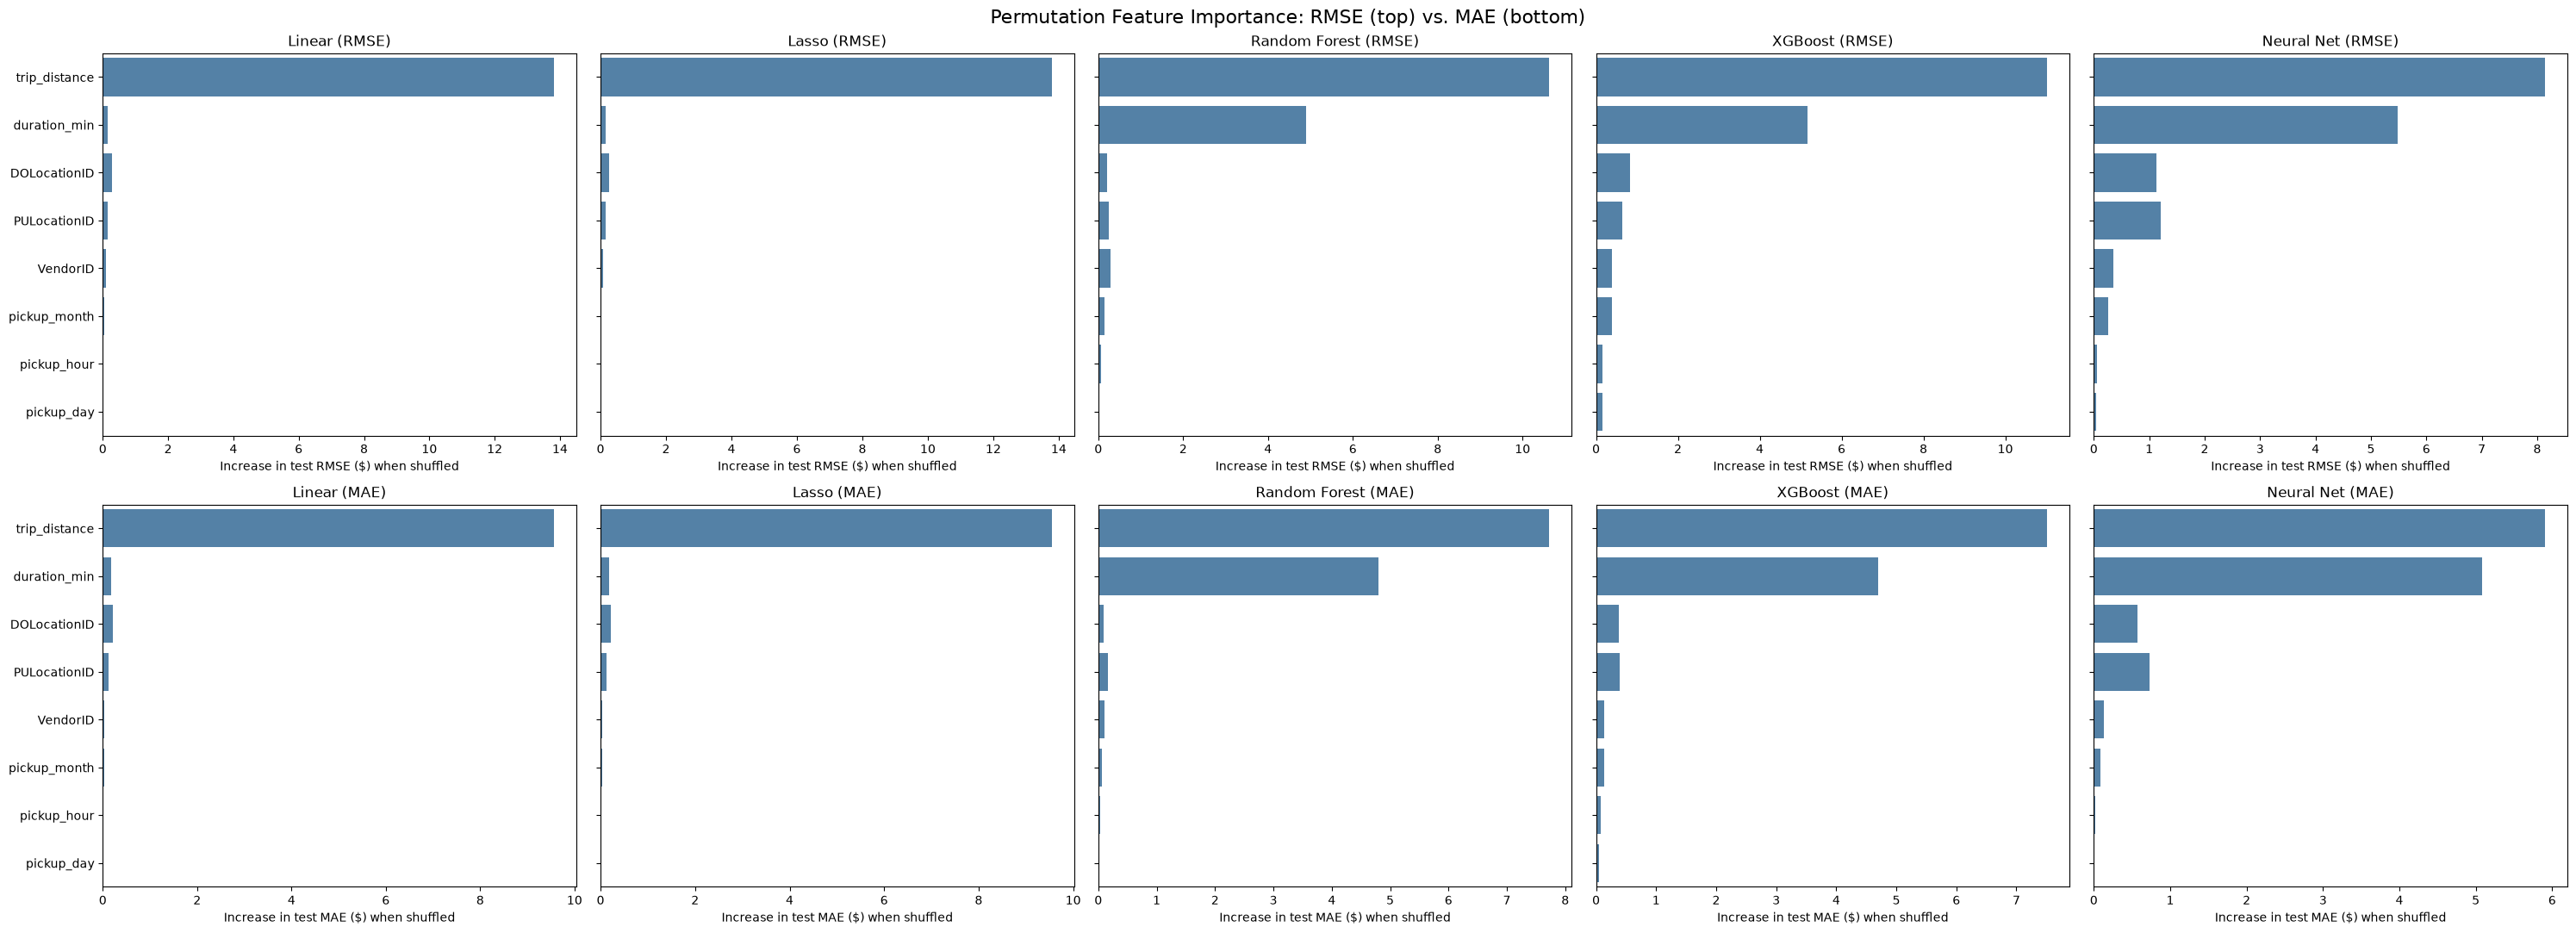

In [15]:
def permutation_importance(predict, X, y, n_repeats=3, seed=42):
    rng = np.random.default_rng(seed)
    base_pred = predict(X)
    base_rmse, base_mae = rmse(y, base_pred), mean_absolute_error(y, base_pred)
    out = {"RMSE": {}, "MAE": {}}
    for col in X.columns:
        r_scores, m_scores = [], []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[col] = rng.permutation(Xp[col].to_numpy())
            p = predict(Xp)
            r_scores.append(rmse(y, p))
            m_scores.append(mean_absolute_error(y, p))
        out["RMSE"][col] = np.mean(r_scores) - base_rmse
        out["MAE"][col] = np.mean(m_scores) - base_mae
    return pd.DataFrame(out)

X_imp = X_test.sample(200_000, random_state=0)
y_imp = y_test.loc[X_imp.index]

# Small models stay in memory; the forest and XGBoost are loaded from disk one
# at a time and freed again, so only one big model is ever in RAM.
model_sources = {
    "Linear": lambda: linear,
    "Lasso": lambda: lasso,
    "Random Forest": lambda: load_model("random_forest"),
    "XGBoost": lambda: load_model("xgboost"),
}
imp = {}
for name, get_model in model_sources.items():
    m = get_model()
    imp[name] = permutation_importance(m.predict, X_imp, y_imp)
    del m
    gc.collect()
# Neural-net importance is computed in NYC-NN.ipynb on the same 200k-row sample
nn_imp_path = MODEL_DIR / "nn_importance.parquet"
if nn_imp_path.exists():
    imp["Neural Net"] = pd.read_parquet(nn_imp_path)
else:
    print("Neural-net importance not found: run NYC-NN.ipynb to include it.")
models = imp   # used below for the number of plot columns
imp_rmse = pd.DataFrame({n: d["RMSE"] for n, d in imp.items()})
imp_mae = pd.DataFrame({n: d["MAE"] for n, d in imp.items()})
order = imp_rmse.mean(axis=1).sort_values(ascending=False).index  # same order in both rows

fig, axes = plt.subplots(2, len(models), figsize=(6 * len(models), 11), sharey=True)
for row, (metric, tbl) in enumerate([("RMSE", imp_rmse), ("MAE", imp_mae)]):
    for ax, model_name in zip(axes[row], tbl.columns):
        sns.barplot(x=tbl.loc[order, model_name], y=order, ax=ax, color="steelblue")
        ax.set_title(f"{model_name} ({metric})")
        ax.set_xlabel(f"Increase in test {metric} ($) when shuffled")
        ax.set_ylabel("")
fig.suptitle("Permutation Feature Importance: RMSE (top) vs. MAE (bottom)", fontsize=16)
plt.tight_layout(); plt.show()

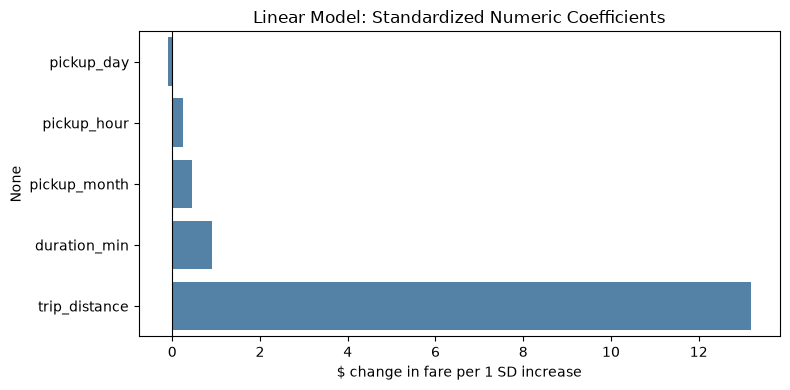

In [16]:
coefs = pd.Series(
    linear.named_steps["reg"].coef_[-len(NUM_COLS):], index=NUM_COLS
).sort_values()
plt.figure(figsize=(8, 4))
sns.barplot(x=coefs.values, y=coefs.index, color="steelblue")
plt.axvline(0, color="k", linewidth=0.8)
plt.xlabel("$ change in fare per 1 SD increase")
plt.title("Linear Model: Standardized Numeric Coefficients")
plt.tight_layout(); plt.show()